### Team 23: Don Le, Raynard Taneka, Krishang Khandelwal

## Title: ????

Install necessary packages

In [1]:
import os
os.environ["GCSFS_EXPERIMENTAL_ZB_HNS_SUPPORT"] = "false"

In [2]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis pandas

In [3]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zarr
import gcsfs

xr.set_options(display_style='html')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [4]:
plt.rcParams['figure.figsize'] = 12, 6

In [5]:
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


Our different scenarios (is what I believe we are looking for)

In [6]:
df.query("activity_id == 'ScenarioMIP'")

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
821,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,wap500,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
822,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFmon,albisccp,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
823,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,ta700,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
824,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,rsutcs,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
825,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,rsut,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
...,...,...,...,...,...,...,...,...,...,...,...
523753,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,tauv,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201
523754,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,tauu,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201
523755,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,ta,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201
523756,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,cli,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201


<h1>Model 1: 3 Spatial Heatmap of each level of ssp for future projections of near surface air termpature per month</h1>

activity_id == 'ScenarioMIP': Future emission scenarios.



table_id == 'Amon': Atmospheric data recorded Monthly 
- <b>Will be important when we decide for the visualization. Sorting by monthly will show us a spatial heatmap. Might be hard to put into an interactive visualization through d3. We can try to find the difference between each spatial heatmap. Might be a little bit hard.</b>
- Suggestion: If we do plan to continue with this, if possible, we should make a slider that the reader can slide through to see every month. And add a button to switch between each ssp.

variable_id == 'tas': Near-surface air temperature. 

experiment_id == 'ssp245': Represents a socioeconomic future that follows historical global trends without major shifts or extremes in technological, economic, or social development. the "middle-of-the-road" scenario.
- ssp126, ssp245, ssp585 is our different emission scenarios. In order from optimistic scenario to high-emission scenario  




In [7]:
df_ta_month_ssp126 = df.query("activity_id == 'ScenarioMIP' & table_id == 'Amon' & variable_id == 'tas' & experiment_id == 'ssp126'")
df_ta_month_ssp126

df_ta_month_ssp245 = df.query("activity_id == 'ScenarioMIP' & table_id == 'Amon' & variable_id == 'tas' & experiment_id == 'ssp245'")
df_ta_month_ssp245

df_ta_month_ssp585 = df.query("activity_id == 'ScenarioMIP' & table_id == 'Amon' & variable_id == 'tas' & experiment_id == 'ssp585'")
df_ta_month_ssp585

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
866,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,Amon,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
19008,ScenarioMIP,NOAA-GFDL,GFDL-ESM4,ssp585,r1i1p1f1,Amon,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-ES...,NaN,20180701
54625,ScenarioMIP,CNRM-CERFACS,CNRM-CM6-1,ssp585,r1i1p1f2,Amon,tas,gr,gs://cmip6/CMIP6/ScenarioMIP/CNRM-CERFACS/CNRM...,NaN,20190219
66586,ScenarioMIP,BCC,BCC-CSM2-MR,ssp585,r1i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/BCC/BCC-CSM2-MR/s...,NaN,20190314
71431,ScenarioMIP,CNRM-CERFACS,CNRM-CM6-1,ssp585,r4i1p1f2,Amon,tas,gr,gs://cmip6/CMIP6/ScenarioMIP/CNRM-CERFACS/CNRM...,NaN,20190410
...,...,...,...,...,...,...,...,...,...,...,...
523257,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r21i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210831
523268,ScenarioMIP,MRI,MRI-ESM2-0,ssp585,r2i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/MRI/MRI-ESM2-0/ss...,NaN,20210907
523318,ScenarioMIP,MRI,MRI-ESM2-0,ssp585,r4i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/MRI/MRI-ESM2-0/ss...,NaN,20210907
523403,ScenarioMIP,MRI,MRI-ESM2-0,ssp585,r5i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/MRI/MRI-ESM2-0/ss...,NaN,20210907


institution_id == 'NASA-GISS': NASA Goddard Institute for Space Studies (GISS). A climate research laboratory located in New York City
- Just picked a random institution. Feel free to see the difference between other institutions.

In [8]:
df_ta_nasa_giss_ssp126 = df_ta_month_ssp126.query("institution_id == 'NASA-GISS'")
df_ta_nasa_giss_ssp126

df_ta_nasa_giss_ssp245 = df_ta_month_ssp245.query("institution_id == 'NASA-GISS'")
df_ta_nasa_giss_ssp245

df_ta_nasa_giss_ssp585 = df_ta_month_ssp585.query("institution_id == 'NASA-GISS'")
df_ta_nasa_giss_ssp585

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
404293,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r2i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
404818,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r3i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
404922,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r2i1p3f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
404941,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r1i1p3f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405045,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r1i1p5f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405111,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r3i1p3f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405121,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r4i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405283,ScenarioMIP,NASA-GISS,GISS-E2-1-H,ssp585,r1i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405457,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r5i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405732,ScenarioMIP,NASA-GISS,GISS-E2-1-H,ssp585,r2i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115


If this cell under does not work, DISABLE adblocker from start up and reset!!!!

In [9]:
# this only needs to be created once
gcs = gcsfs.GCSFileSystem(token='anon')

# get the path to a specific zarr store (the first one from the dataframe above)
zstore_month_ssp126 = df_ta_nasa_giss_ssp126.iloc[0].zstore
zstore_month_ssp245 = df_ta_nasa_giss_ssp245.iloc[0].zstore
zstore_month_ssp585 = df_ta_nasa_giss_ssp585.iloc[0].zstore

# create a mutable-mapping-style interface to the store
mapper_ssp126 = gcs.get_mapper(zstore_month_ssp126)
mapper_ssp245 = gcs.get_mapper(zstore_month_ssp245)
mapper_ssp585 = gcs.get_mapper(zstore_month_ssp585)

# open it using xarray and zarr
ds_month_ssp126 = xr.open_zarr(mapper_ssp126, consolidated=True)
ds_month_ssp245 = xr.open_zarr(mapper_ssp245, consolidated=True)
ds_month_ssp585 = xr.open_zarr(mapper_ssp585, consolidated=True)
ds_month_ssp585 # preview of the dataset

C:\Users\cryst\AppData\Local\Temp\ipykernel_23192\3870950360.py:17: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds_month_ssp585 = xr.open_zarr(mapper_ssp585, consolidated=True)


<xarray.Dataset> Size: 178MB
Dimensions:    (time: 3432, lat: 90, lon: 144, bnds: 2)
Coordinates:
  * time       (time) object 27kB 2015-01-16 12:00:00 ... 2300-12-16 12:00:00
  * lat        (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 85.0 87.0 89.0
  * lon        (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
    lat_bnds   (lat, bnds) float64 1kB ...
    lon_bnds   (lon, bnds) float64 2kB ...
    time_bnds  (time, bnds) object 55kB ...
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    tas        (time, lat, lon) float32 178MB ...
Attributes: (12/51)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            ScenarioMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.3.2
    ...                     ...
    table_info:             Creation Date:(21 March 2018) MD5:1fc78f7af4d0af8...
    title:                  GISS-E2-1-G output prepared for CMIP6
    tracking_id:            hdl:21.14100/f20dc809-0baa-4dbb-830d-11a4cf007346
    variable_id:            tas
    variant_label:          r2i1p1f2
    version_id:             v20200115

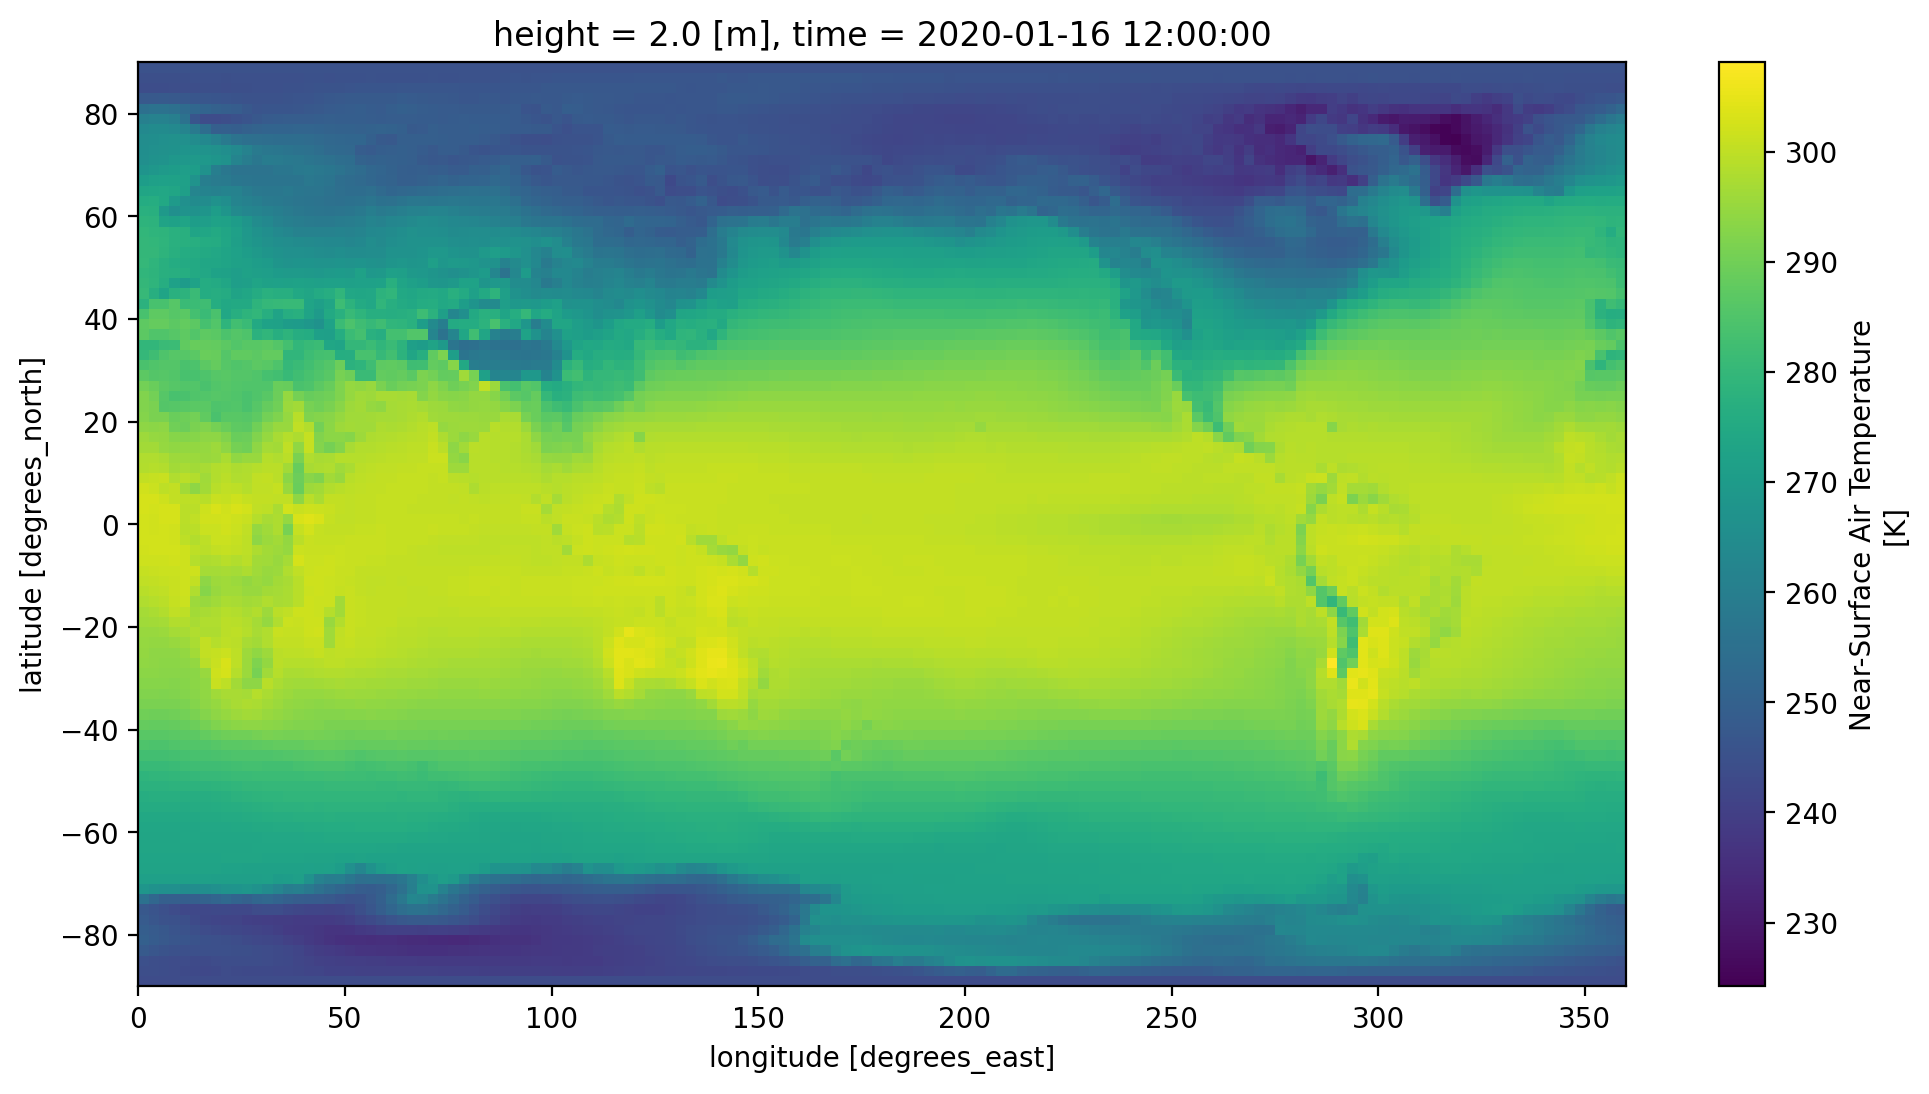

In [10]:
ds_month_ssp126.tas.sel(time='2020-01').squeeze().plot()

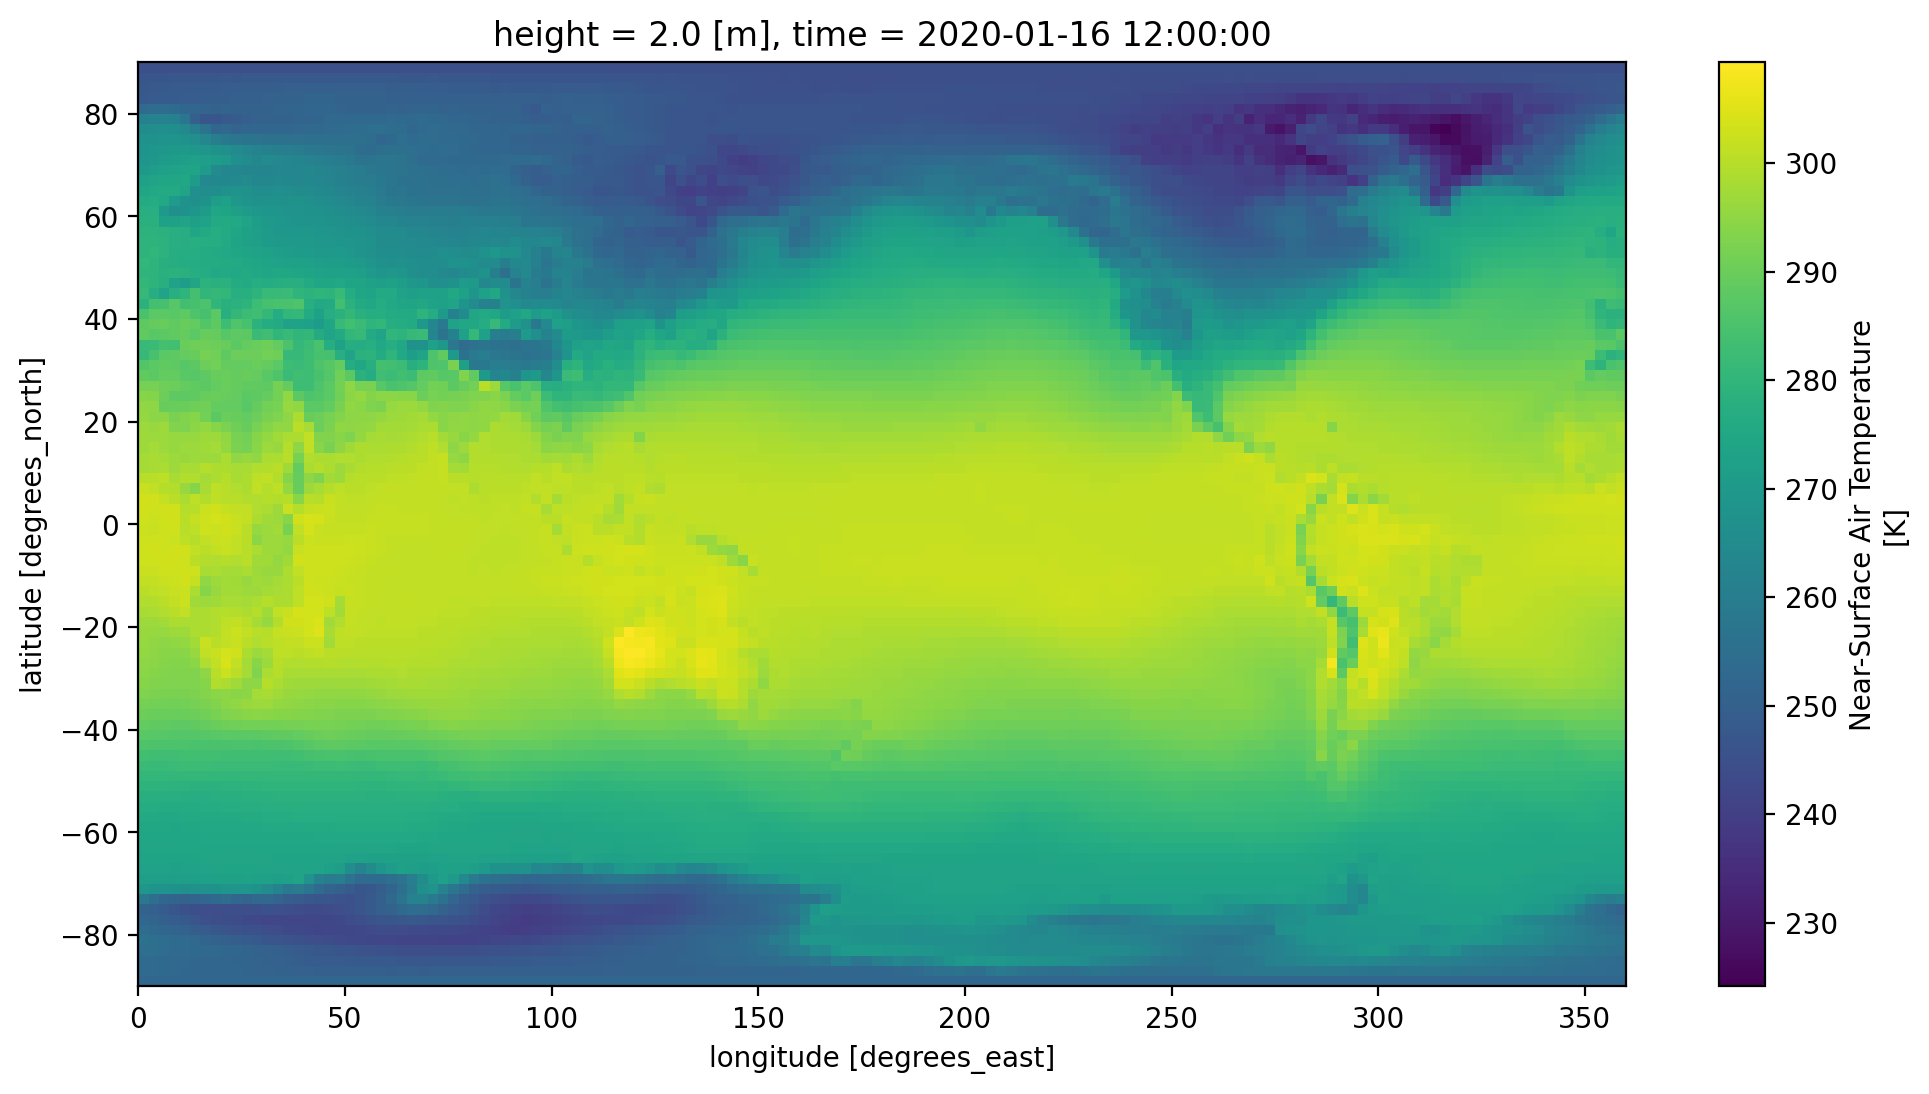

In [11]:
ds_month_ssp245.tas.sel(time='2020-01').squeeze().plot()

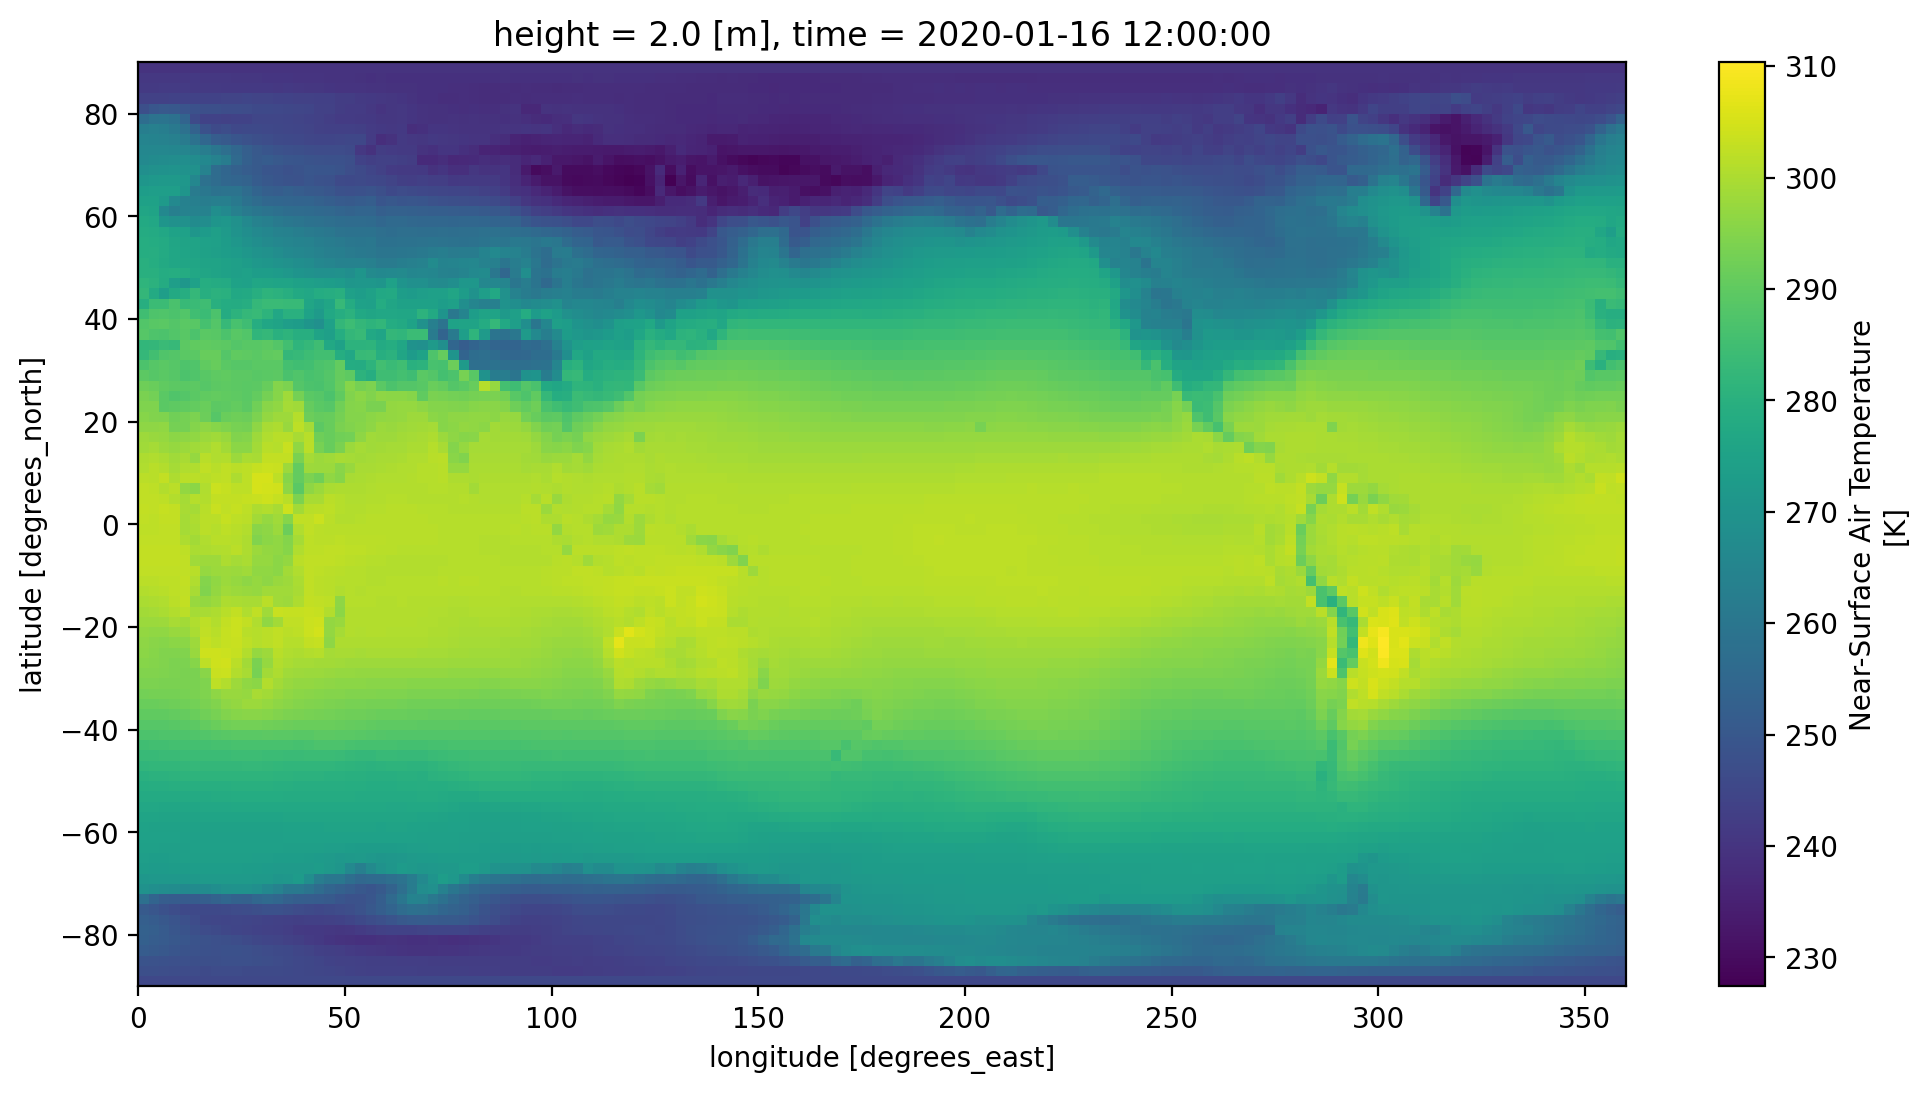

In [12]:
ds_month_ssp585.tas.sel(time='2020-01').squeeze().plot()

There isn't that much difference between ssp126 and ssp245. But from ssp126 and ssp585, there is an apparent difference in air temperature especially in the north area. 

<b>Can help us identify what areas are affected the most from looking at these 3 models.</b>

Overall I think this is a good visualization that we can implement interactive elements to it. The problem is difficulty.

My Suggestions: We can either try to somehow output another heatmap that shows the difference in  air temperature between ssp126 and ssp585 across certain months or have them overlap and the user can just toggle between the scenarios.

### Difference heatmap: ssp585 − ssp126

Since both scenarios come from the same model and grid (GISS-E2-1-G, `gn`), the two `tas` DataArrays share identical `lat`/`lon` coordinates, so we can subtract them directly — xarray aligns on the shared coordinates automatically. A diverging colormap (`RdBu_r`) centered at 0 makes it easy to read: **red = ssp585 warmer than ssp126**, **blue = ssp585 cooler**.

In [13]:
def plot_tas_diff(ds_high, ds_low, time, label_high="ssp585", label_low="ssp126"):
    """Plot the near-surface air temperature difference (ds_high - ds_low) for a given time."""
    tas_high = ds_high.tas.sel(time=time).squeeze()
    tas_low = ds_low.tas.sel(time=time).squeeze()
    diff = tas_high - tas_low

    fig, ax = plt.subplots(figsize=(12, 6))
    diff.plot(
        ax=ax,
        cmap='RdBu_r',
        center=0,
        cbar_kwargs={'label': f'{label_high} minus {label_low} Near-Surface Air Temperature [K]'}
    )
    ax.set_title(f'Temperature Difference ({label_high} − {label_low}), {time}')
    plt.show()
    return diff

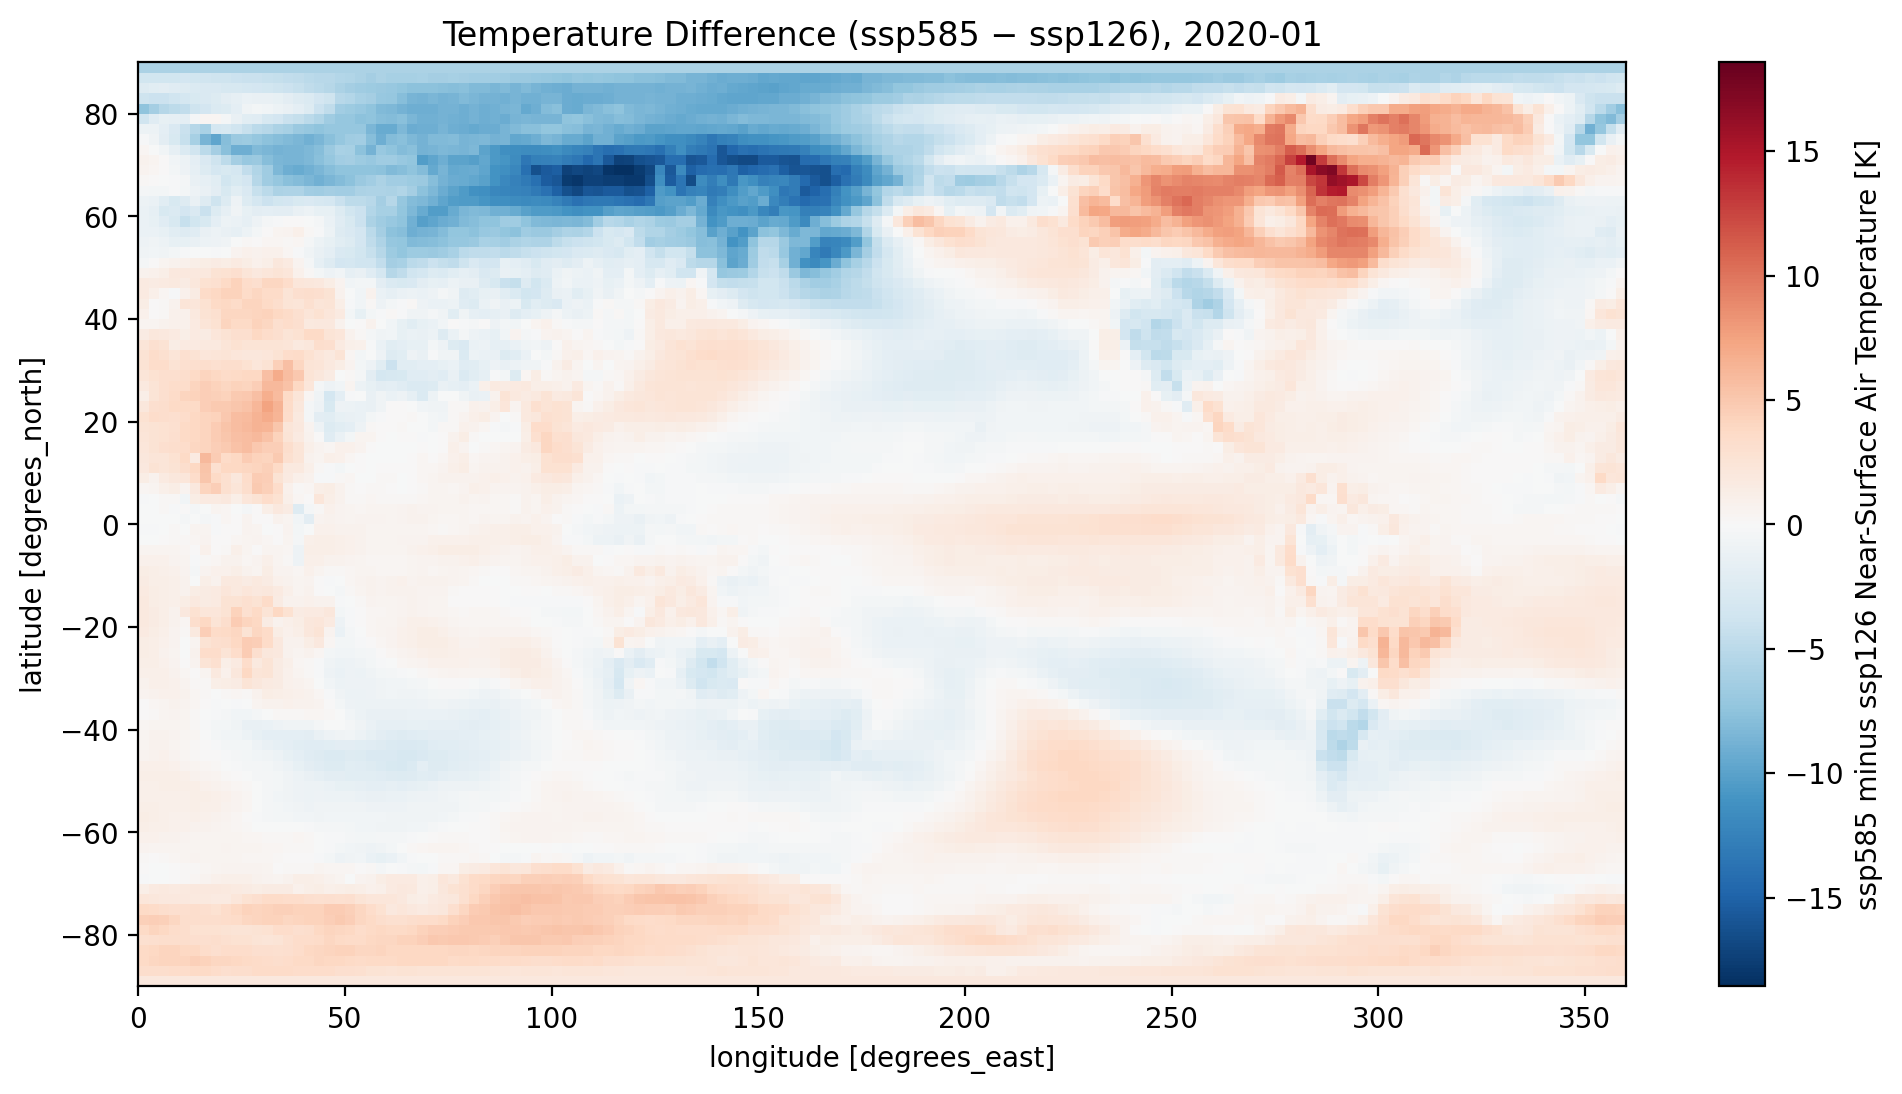

In [14]:
diff_2020 = plot_tas_diff(ds_month_ssp585, ds_month_ssp126, '2020-01')

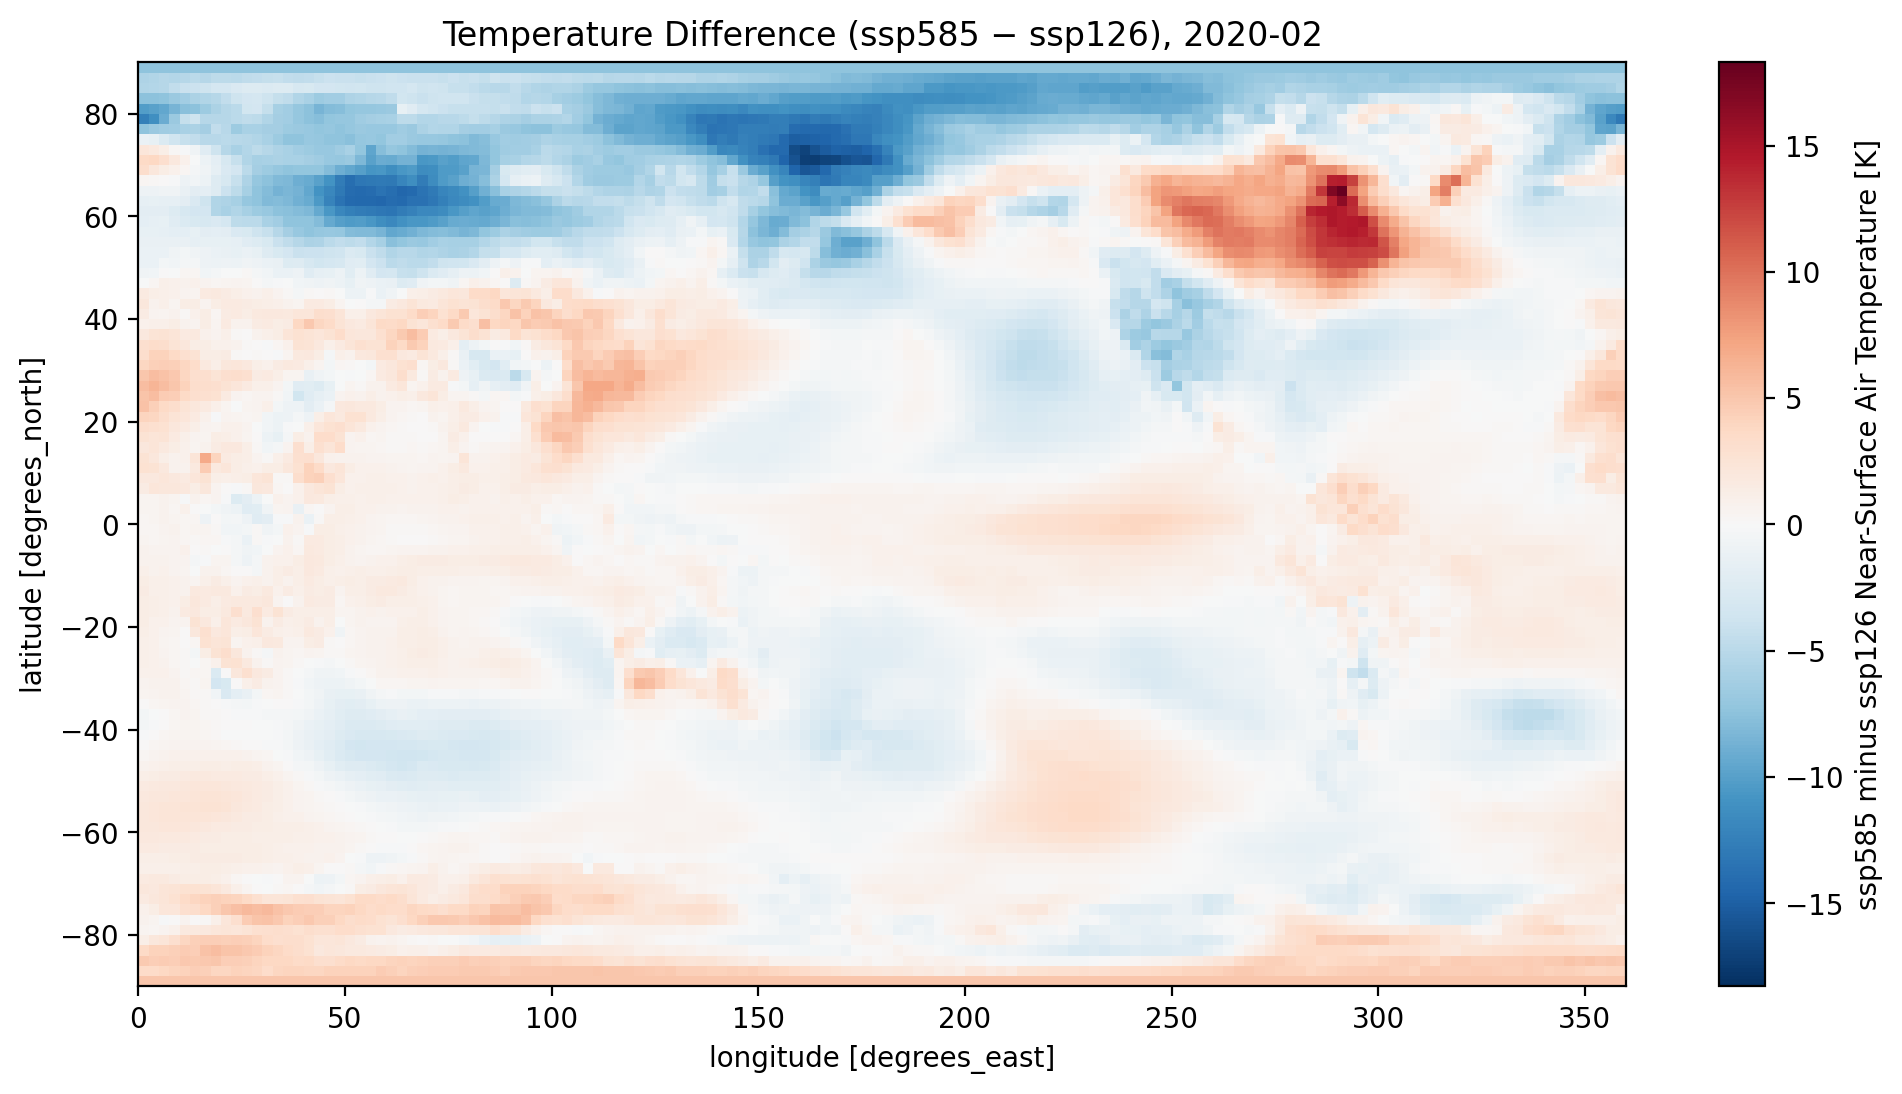

In [15]:
diff_2020 = plot_tas_diff(ds_month_ssp585, ds_month_ssp126, '2020-02')


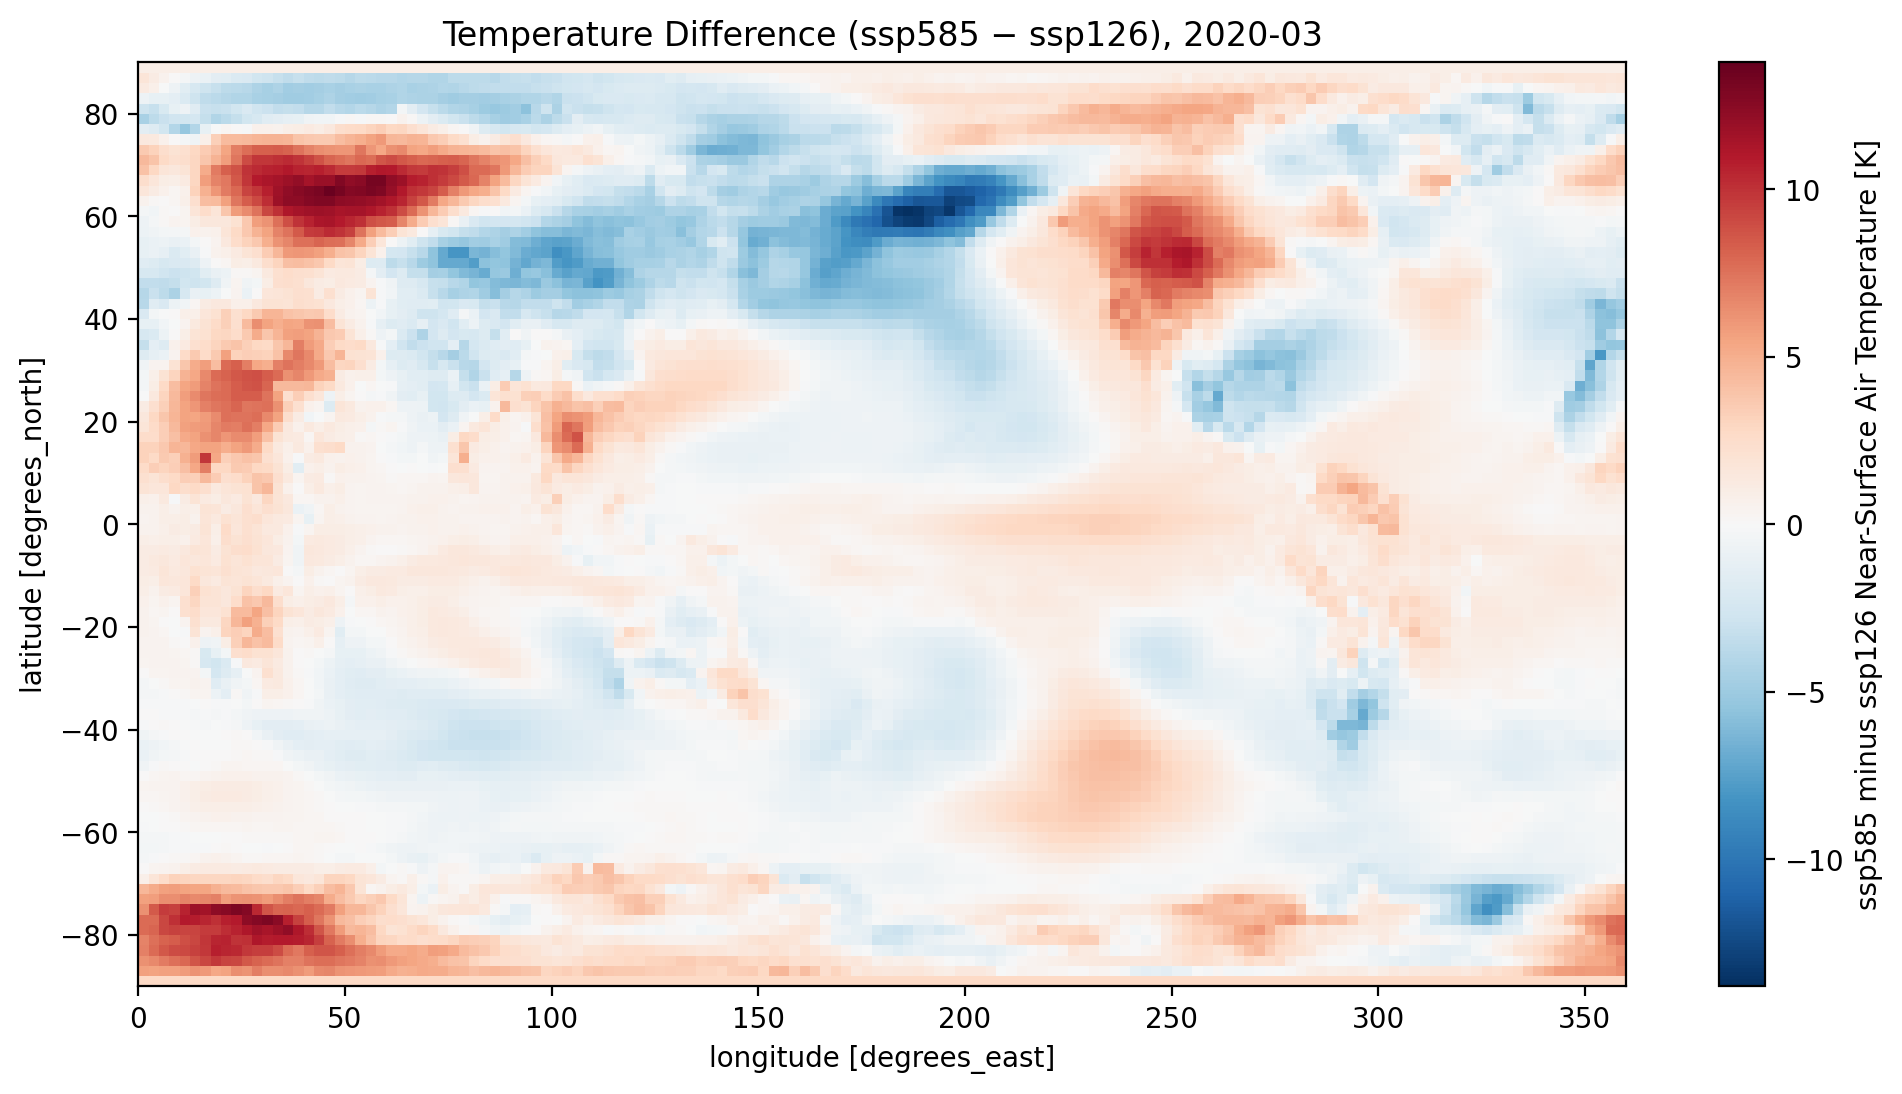

In [16]:
diff_2020 = plot_tas_diff(ds_month_ssp585, ds_month_ssp126, '2020-03')

### Same thing, but for every month in a given year

Instead of picking one month at a time, select the whole year from both datasets (12 monthly time steps each), subtract, and let xarray lay the 12 resulting maps out as a grid of small multiples (`col='time'`) sharing one colorbar — essentially your "slider through the months" idea, just rendered as a grid instead of an interactive control.

C:\Users\cryst\AppData\Local\Temp\ipykernel_23192\1784534650.py:18: FutureWarning: self.axes is deprecated since 2022.11 in order to align with matplotlibs plt.subplots, use self.axs instead.
  for ax, t in zip(fg.axes.flat, diff.time.values):


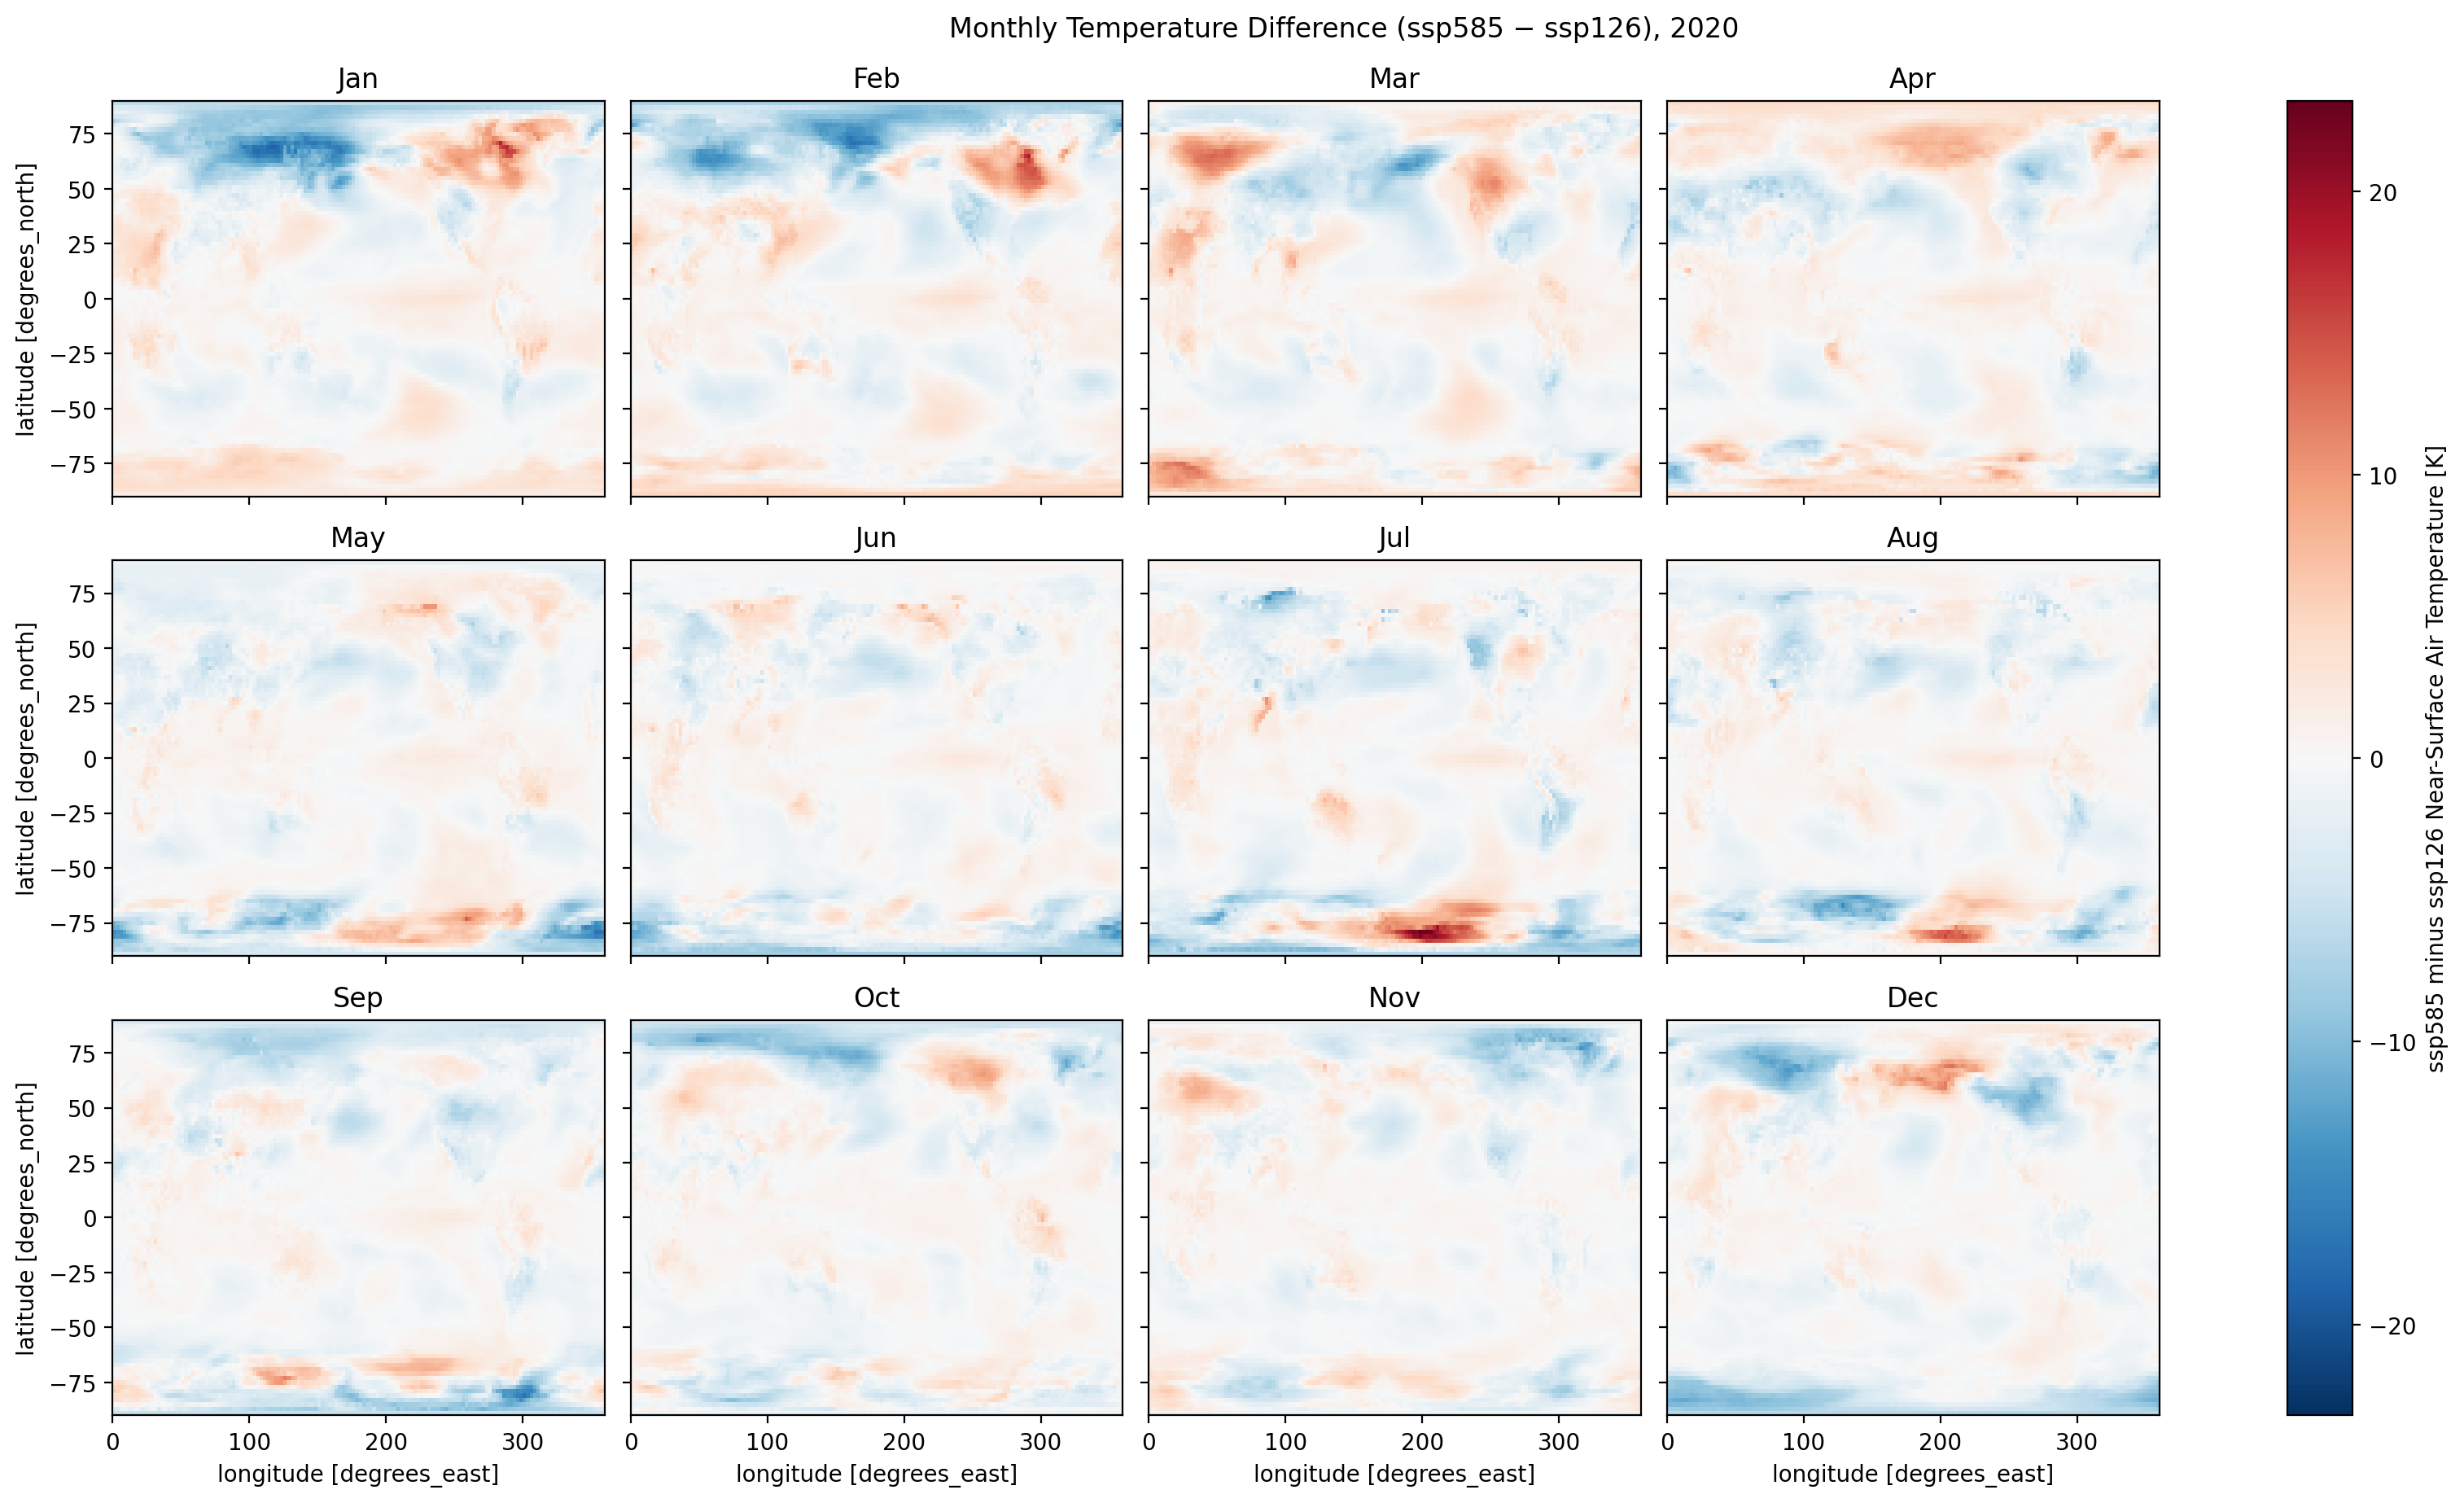

In [17]:
def plot_tas_diff_year(ds_high, ds_low, year, label_high="ssp585", label_low="ssp126", col_wrap=4):
    """Plot the near-surface air temperature difference (ds_high - ds_low) for every month of a given year."""
    tas_high = ds_high.tas.sel(time=str(year))
    tas_low = ds_low.tas.sel(time=str(year))
    diff = (tas_high - tas_low).squeeze()

    fg = diff.plot(
        col='time',
        col_wrap=col_wrap,
        cmap='RdBu_r',
        center=0,
        size=3,
        aspect=1.3,
        cbar_kwargs={'label': f'{label_high} minus {label_low} Near-Surface Air Temperature [K]'}
    )
    fg.fig.suptitle(f'Monthly Temperature Difference ({label_high} − {label_low}), {year}', y=1.02)
    # replace the default "time = ..." titles with just the month name
    for ax, t in zip(fg.axes.flat, diff.time.values):
        ax.set_title(t.strftime('%b'))
    plt.show()
    return diff

diff_2020_all_months = plot_tas_diff_year(ds_month_ssp585, ds_month_ssp126, 2020)

### Objective
What I want to do is to make a visualization with the heatmap. As the user scrolls through the months, the heatmap would change according to the month's heatmap (like a timelapse type of thing). Not sure how we can make this with d3. We can also add some other interactive features on top of the slider like mouseover and such.

<h1>Model 2 (Plan B): Bar Chart of ssp245 about future projections of near surface air termpature per day</h1>

In [18]:
df_ta_day_ssp126 = df.query("activity_id == 'ScenarioMIP' & table_id == 'day' & variable_id == 'tas' & experiment_id == 'ssp126'")
df_ta_day_ssp126

df_ta_day_ssp245 = df.query("activity_id == 'ScenarioMIP' & table_id == 'day' & variable_id == 'tas' & experiment_id == 'ssp245'")
df_ta_day_ssp245

df_ta_day_ssp585 = df.query("activity_id == 'ScenarioMIP' & table_id == 'day' & variable_id == 'tas' & experiment_id == 'ssp585'")
df_ta_day_ssp585

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
11407,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,day,tas,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
11408,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,day,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
11538,ScenarioMIP,NOAA-GFDL,GFDL-ESM4,ssp585,r1i1p1f1,day,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-ES...,NaN,20180701
54334,ScenarioMIP,CNRM-CERFACS,CNRM-CM6-1,ssp585,r1i1p1f2,day,tas,gr,gs://cmip6/CMIP6/ScenarioMIP/CNRM-CERFACS/CNRM...,NaN,20190219
66710,ScenarioMIP,BCC,BCC-CSM2-MR,ssp585,r1i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/BCC/BCC-CSM2-MR/s...,NaN,20190318
...,...,...,...,...,...,...,...,...,...,...,...
517941,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r9i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210318
517958,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r10i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210318
518011,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r8i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210318
520066,ScenarioMIP,NIMS-KMA,UKESM1-0-LL,ssp585,r15i1p1f2,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NIMS-KMA/UKESM1-0...,NaN,20210428


In [26]:
df_ta_day_nasa_giss_ssp126 = df_ta_day_ssp126.query("institution_id == 'NASA-GISS'")
df_ta_day_nasa_giss_ssp126

df_ta_day_nasa_giss_ssp245 = df_ta_day_ssp245.query("institution_id == 'NASA-GISS'")
df_ta_day_nasa_giss_ssp245

df_ta_day_nasa_giss_ssp585 = df_ta_day_ssp585.query("institution_id == 'NASA-GISS'")
df_ta_day_nasa_giss_ssp126


,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
403832,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp126,r1i1p3f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
406114,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp126,r1i1p5f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115


In [31]:
zstore_day_ssp126 = df_ta_day_nasa_giss_ssp126.iloc[1].zstore
zstore_day_ssp245 = df_ta_day_nasa_giss_ssp245.iloc[0].zstore
zstore_day_ssp585 = df_ta_day_nasa_giss_ssp585.iloc[0].zstore

# create a mutable-mapping-style interface to the store
mapper_day_ssp126 = gcs.get_mapper(zstore_day_ssp126)
mapper_day_ssp245 = gcs.get_mapper(zstore_day_ssp245)
mapper_day_ssp585 = gcs.get_mapper(zstore_day_ssp585)


# open it using xarray and zarr
ds_day_ssp126 = xr.open_zarr(mapper_day_ssp126, consolidated=True)
ds_day_ssp245 = xr.open_zarr(mapper_day_ssp245, consolidated=True)
ds_day_ssp585 = xr.open_zarr(mapper_day_ssp585, consolidated=True)


ds_day_ssp126

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 31390, lat: 90, lon: 144, bnds: 2)
Coordinates:
  * time       (time) object 251kB 2015-01-01 12:00:00 ... 2100-12-31 12:00:00
  * lat        (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 85.0 87.0 89.0
  * lon        (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
    lat_bnds   (lat, bnds) float64 1kB ...
    lon_bnds   (lon, bnds) float64 2kB ...
    time_bnds  (time, bnds) object 502kB ...
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    tas        (time, lat, lon) float32 2GB ...
Attributes: (12/49)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            ScenarioMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.3.2
    ...                     ...
    table_id:               day
    table_info:             Creation Date:(21 March 2018) MD5:d211846f9d8f448...
    title:                  GISS-E2-1-G output prepared for CMIP6
    tracking_id:            hdl:21.14100/42cc3bcc-068c-4ec8-bc9a-0f40cd9eb0a6
    variable_id:            tas
    variant_label:          r1i1p5f1

(array([   390.,   4530.,  29631.,  49528.,  26724.,  41589.,  63465.,
         57037., 127065.,   1801.]),
 array([213.30628967, 223.39225769, 233.47822571, 243.56419373,
        253.650177  , 263.73614502, 273.82211304, 283.90808105,
        293.99404907, 304.08001709, 314.16598511]),
 <BarContainer object of 10 artists>)

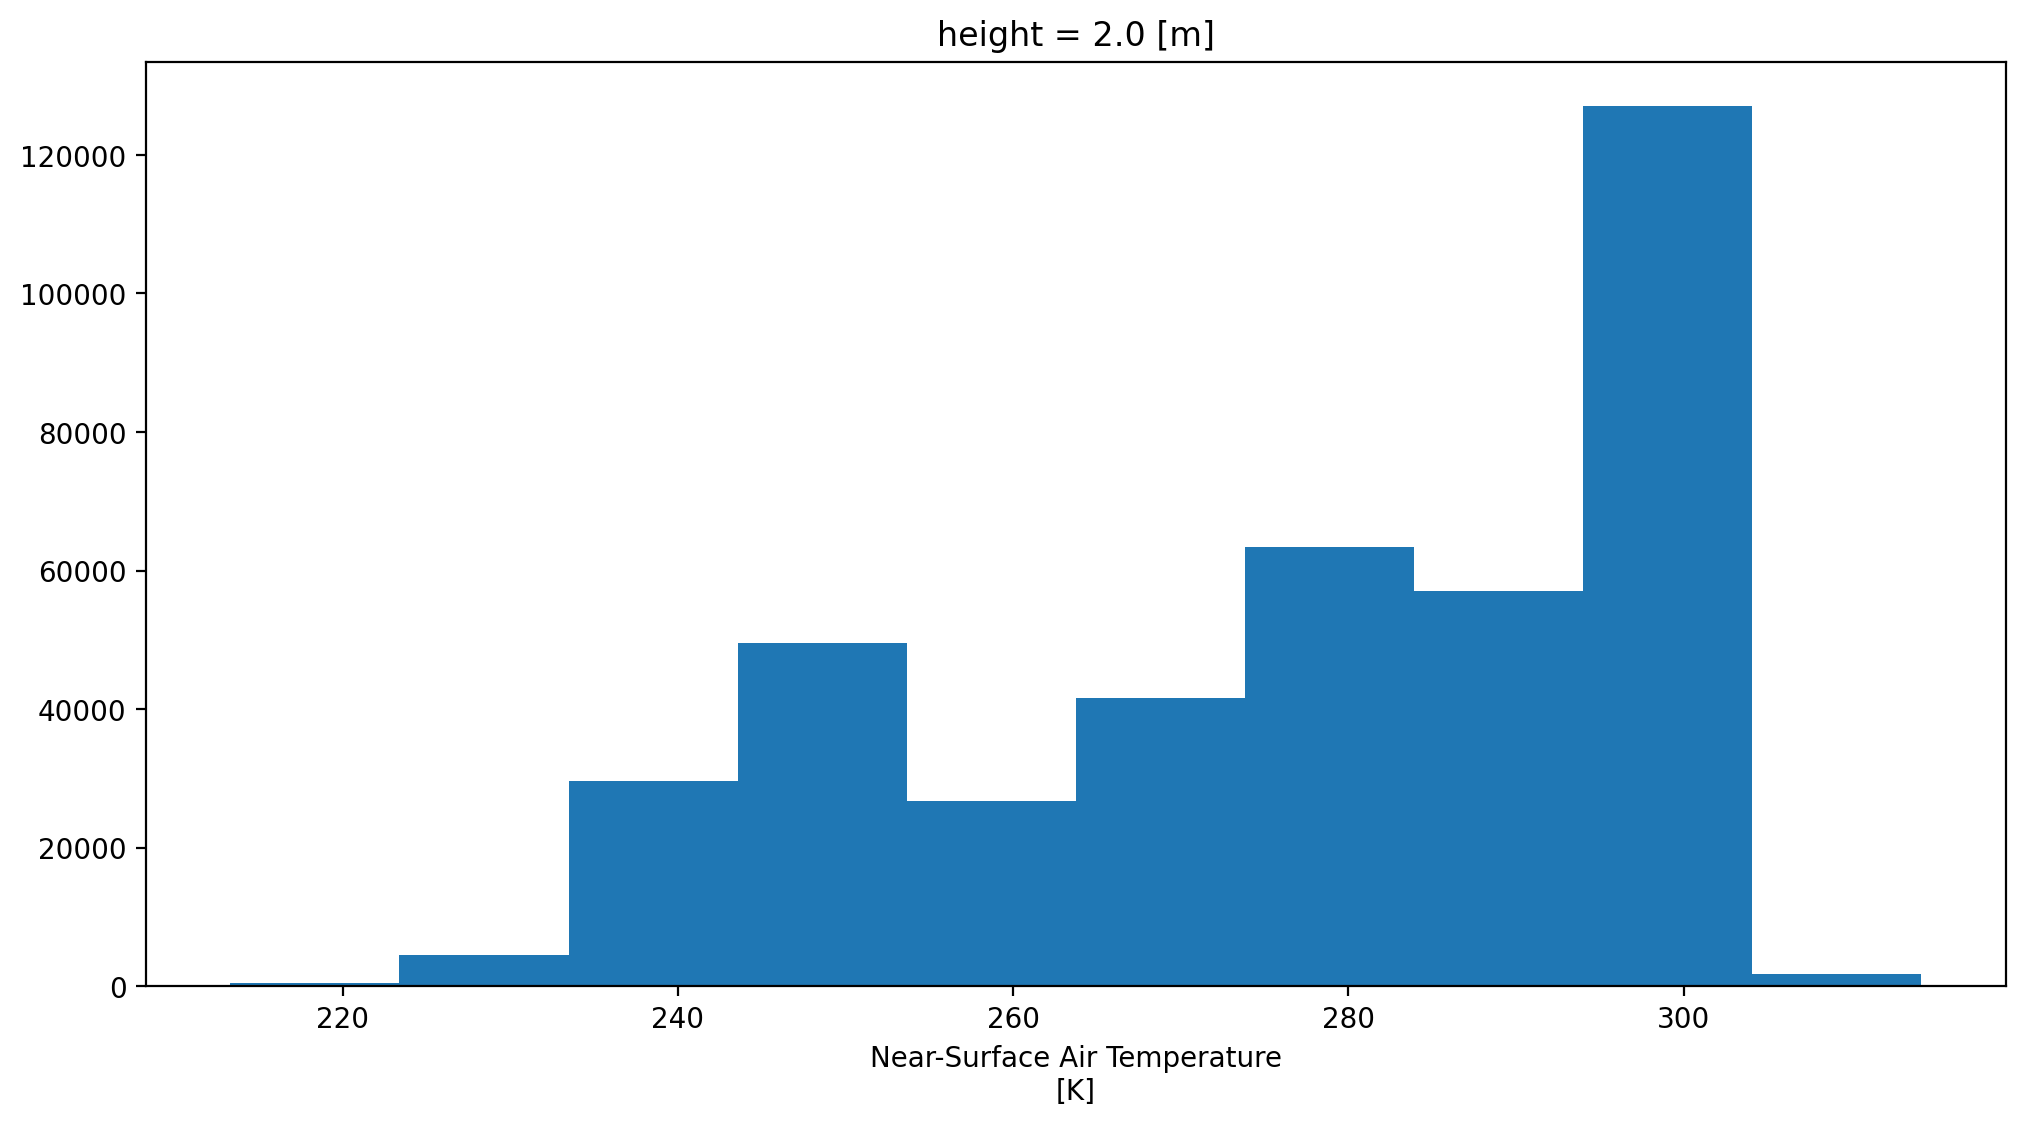

In [ ]:
ds_day_ssp126.tas.sel(time='2015-01').squeeze().plot() #This is 2015

(array([   261.,   2639.,  19000.,  50260.,  37463.,  49076.,  61859.,
         58675., 120642.,   1885.]),
 array([212.90377808, 223.11994934, 233.33612061, 243.55227661,
        253.76844788, 263.98461914, 274.20080566, 284.41696167,
        294.63311768, 304.8493042 , 315.06546021]),
 <BarContainer object of 10 artists>)

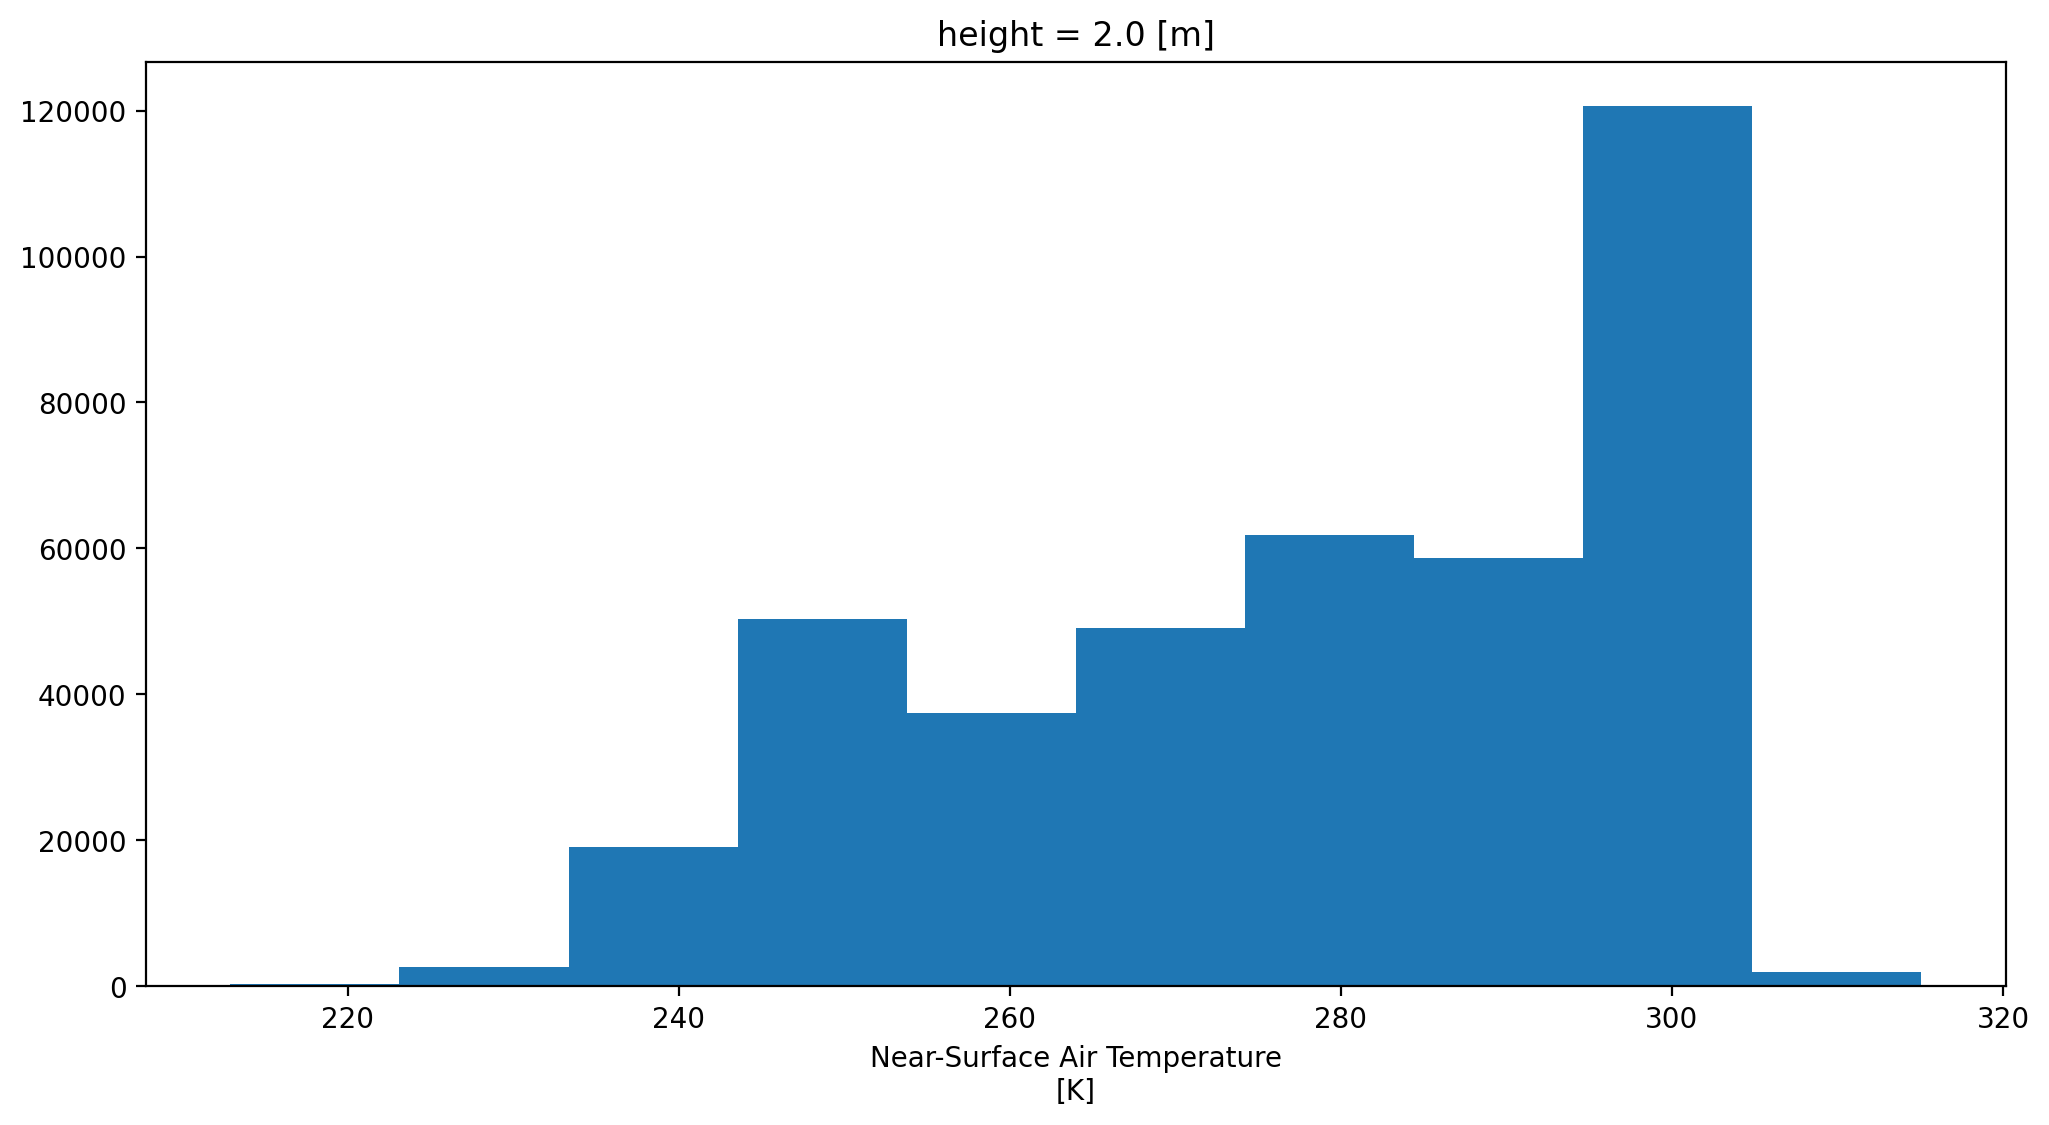

In [ ]:
ds_day_ssp245.tas.sel(time='2020-01').squeeze().plot() #This is 2020

(array([   309.,   4607.,  31999.,  42399.,  27320.,  39802.,  65379.,
         57823., 123126.,   8996.]),
 array([212.82806396, 222.92492676, 233.02180481, 243.1186676 ,
        253.21554565, 263.31240845, 273.40927124, 283.50613403,
        293.60302734, 303.69989014, 313.79675293]),
 <BarContainer object of 10 artists>)

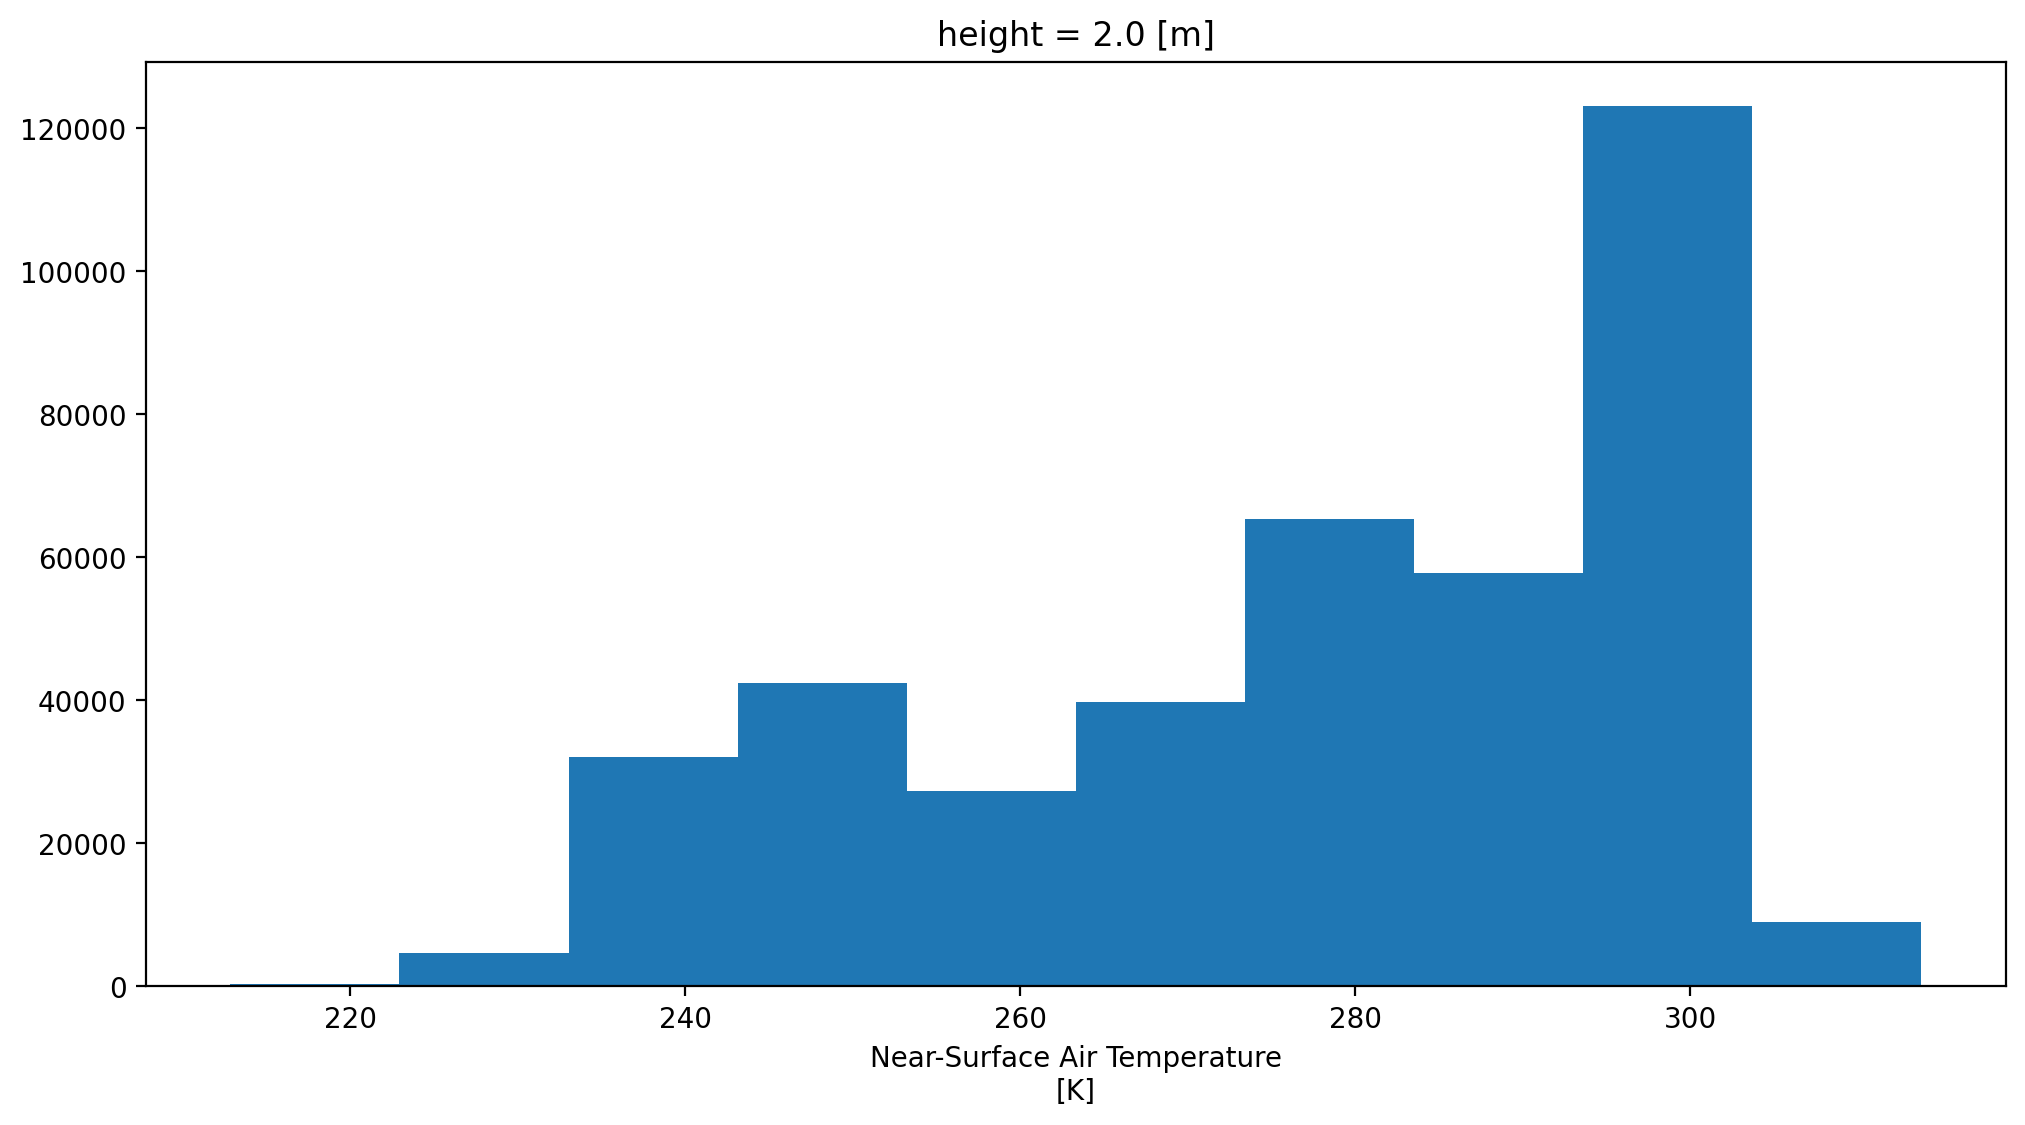

In [ ]:
ds_day_ssp585.tas.sel(time='2020-01').squeeze().plot()

With the bar chart, is is very hard to understand the difference at one glance. And its kind of plain...